# Lab 14.2: Five Attributions for One Token

Chapter 14, *Why Language Models Are Hard to Explain*. Run the cells from top to bottom; no code needs to be written. One cell near the end invites you to change a sentence.

We ask GPT-2 small why, after "The nurse who interviewed the engineer said that", the next token " she" is more likely than " he". Five methods answer: last-layer attention, attention rollout, gradient times input, integrated gradients and occlusion. Then we vary the replacement used by occlusion, change the target from contrastive to plain, and test agreement across 30 sentences.

Environment: `env/requirements-llm.txt` (torch 2.6.0, transformer-lens 2.18.0). GPT-2 small (about 500 MB) downloads on first use.

In [1]:
import time, itertools
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from transformer_lens import HookedTransformer

torch.manual_seed(0)
t0 = time.time()
model = HookedTransformer.from_pretrained("gpt2", device="cpu")
model.eval()
print("layers:", model.cfg.n_layers, "heads per layer:", model.cfg.n_heads, "width:", model.cfg.d_model, "vocabulary:", model.cfg.d_vocab)

Loaded pretrained model gpt2 into HookedTransformer
layers: 12 heads per layer: 12 width: 768 vocabulary: 50257


## 1. The prediction and the target

The **target** is what we explain. A contrastive target, the logit of " she" minus the logit of " he", asks "why she rather than he?". A plain target, the log probability of " she", asks "why she at all?".

In [2]:
SHE, HE = model.to_single_token(" she"), model.to_single_token(" he")
MEAN_E = model.W_E.mean(0).detach()

def target_value(logits, kind):
    last = logits[:, -1]
    if kind == "diff":
        return last[:, SHE] - last[:, HE]
    return last.log_softmax(-1)[:, SHE]

def run_with_embeddings(tokens, E, kind):
    # E has shape (batch, positions, width); positions are added by the model as usual
    tok = tokens.expand(E.shape[0], -1)
    logits = model.run_with_hooks(tok, fwd_hooks=[("hook_embed", lambda act, hook: E)])
    return target_value(logits, kind)

sentence = "The nurse who interviewed the engineer said that"
tokens = model.to_tokens(sentence)
labels = ["[start]" if t == "<|endoftext|>" else t.strip() for t in model.to_str_tokens(sentence)]
with torch.no_grad():
    probs = model(tokens)[0, -1].softmax(-1)
print(labels)
print("p(she) = %.3f, p(he) = %.3f" % (probs[SHE], probs[HE]))
top = probs.topk(5)
print("top five next tokens:", [(model.to_string(i), round(v.item(), 3)) for v, i in zip(top.values, top.indices)])

['[start]', 'The', 'nurse', 'who', 'interviewed', 'the', 'engineer', 'said', 'that']
p(she) = 0.176, p(he) = 0.096
top five next tokens: [(' she', 0.176), (' the', 0.135), (' he', 0.096), (' when', 0.048), (' her', 0.04)]


**Checkpoint 1:** p(she) = 0.176 and p(he) = 0.096; " she" is the most likely next token.

## 2. Five attributions

All five are computed for the contrastive target. Occlusion cannot remove the start token, so it shows `nan` there.

In [3]:
def attributions(tokens, kind="diff", ig_steps=32):
    n = tokens.shape[1]
    E0 = model.W_E[tokens[0]].detach().unsqueeze(0)
    out = {}
    # gradient times input
    E = E0.clone().requires_grad_(True)
    run_with_embeddings(tokens, E, kind).sum().backward()
    out["grad x input"] = (E.grad * E).sum(-1)[0].detach().numpy()
    # integrated gradients from an all-zero embedding, all steps in one batch
    alphas = ((torch.arange(ig_steps) + 0.5) / ig_steps).view(-1, 1, 1)
    Ea = (alphas * E0).clone().requires_grad_(True)
    run_with_embeddings(tokens, Ea, kind).sum().backward()
    out["integrated gradients"] = (Ea.grad.mean(0) * E0[0]).sum(-1).detach().numpy()
    with torch.no_grad():
        base = target_value(model(tokens), kind).item()
        # occlusion by deletion: one shorter sentence per removed token, in one batch
        dels = torch.stack([torch.cat([tokens[0, :i], tokens[0, i + 1:]]) for i in range(1, n)])
        out["delete"] = np.r_[np.nan, base - target_value(model(dels), kind).numpy()]
        # replace with the average embedding
        Em = E0.repeat(n - 1, 1, 1)
        for k, i in enumerate(range(1, n)):
            Em[k, i] = MEAN_E
        out["average embedding"] = np.r_[np.nan, base - run_with_embeddings(tokens, Em, kind).numpy()]
        # replace with the end-of-text token
        eos = tokens.repeat(n - 1, 1)
        for k, i in enumerate(range(1, n)):
            eos[k, i] = model.tokenizer.eos_token_id
        out["end-of-text"] = np.r_[np.nan, base - target_value(model(eos), kind).numpy()]
        _, cache = model.run_with_cache(tokens)
        out["attention (last layer)"] = cache["pattern", model.cfg.n_layers - 1][0, :, -1, :].mean(0).numpy()
        R = np.eye(n)
        for L in range(model.cfg.n_layers):
            A = cache["pattern", L][0].mean(0).numpy()
            A = 0.5 * A + 0.5 * np.eye(n)
            A /= A.sum(-1, keepdims=True)
            R = A @ R
        out["attention rollout"] = R[-1]
    out["base"] = base
    return out

res = attributions(tokens, "diff")
print("she-minus-he logit: %.2f" % res["base"])
rows = ["attention (last layer)", "attention rollout", "grad x input", "integrated gradients", "delete"]
print("%-24s" % "", " ".join("%11s" % l[:11] for l in labels))
for r in rows:
    print("%-24s" % r, " ".join("%11.2f" % v for v in res[r]))
print("integrated gradients add up to %.2f" % np.nansum(res["integrated gradients"]))

she-minus-he logit: 0.61
                             [start]         The       nurse         who interviewed         the    engineer        said        that
attention (last layer)          0.61        0.04        0.05        0.04        0.02        0.02        0.05        0.08        0.09
attention rollout               0.99        0.00        0.00        0.00        0.00        0.00        0.00        0.00        0.00
grad x input                    0.20       -0.02       -0.04       -0.11       -0.05        0.27        0.44       -0.01        0.06
integrated gradients            1.58        1.12        0.21        0.77       -0.00        0.66       -0.67       -0.35        0.40
delete                           nan        0.06        2.59        0.08        0.71       -1.23       -1.58        0.06       -0.01
integrated gradients add up to 3.70


**Checkpoint 2:** last-layer attention puts 0.61 on `[start]` and rollout 0.99; gradient times input gives its largest score (0.44) to *engineer*; integrated gradients gives about 1.58 to `[start]` and adds up to about 3.7 (the chapter's figure used 48 steps and gets 3.75); deletion gives +2.59 to *nurse* and -1.58 to *engineer*. Small differences in the second decimal can occur with other library versions.

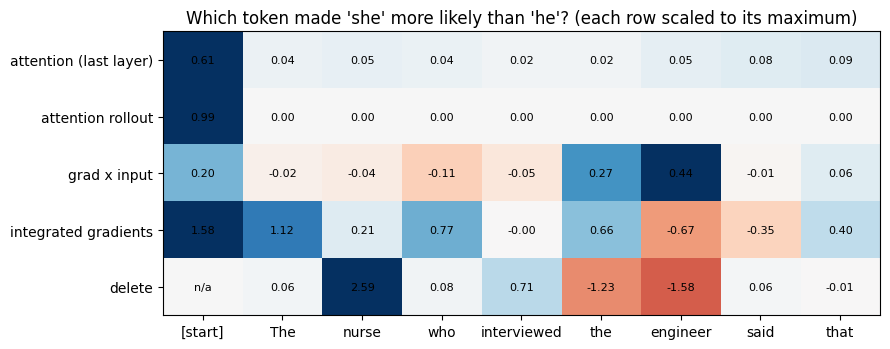

In [4]:
M = np.array([res[r] / np.nanmax(np.abs(res[r])) for r in rows])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.imshow(np.nan_to_num(M), cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
for i, r in enumerate(rows):
    for j in range(len(labels)):
        v = res[r][j]
        ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(labels)), labels)
ax.set_yticks(range(len(rows)), rows)
ax.set_title("Which token made 'she' more likely than 'he'? (each row scaled to its maximum)")
plt.tight_layout(); plt.show()

## 3. What does "remove a token" mean?

Occlusion needs a replacement. Compare deletion, the average embedding and the end-of-text token.

In [5]:
for r in ["delete", "average embedding", "end-of-text"]:
    print("%-18s" % r, " ".join("%7.2f" % v for v in res[r][1:]))
print("%-18s" % "", " ".join("%7s" % l[:7] for l in labels[1:]))

delete                0.06    2.59    0.08    0.71   -1.23   -1.58    0.06   -0.01
average embedding     0.32    2.92    0.27    0.80   -1.03   -1.71    0.63    0.56
end-of-text           0.29    2.94    1.96    2.15    2.23    0.80    1.59    1.96
                       The   nurse     who intervi     the enginee    said    that


**Checkpoint 3:** deletion and the average embedding agree on the big effects (*nurse* about +2.6 and +2.9, *engineer* about -1.6 and -1.7). The end-of-text replacement makes every token positive, *engineer* included (+0.80).

## 4. Plain versus contrastive target

In [6]:
plain = attributions(tokens, "logp")
print("log p(she) = %.2f" % plain["base"])
for name, r in [("why she?", plain), ("why she rather than he?", res)]:
    v = r["delete"][1:]
    print("%-24s top token by deletion: %-8s (%.2f)" % (name, labels[1:][int(np.nanargmax(v))], np.nanmax(v)))

log p(she) = -1.74
why she?                 top token by deletion: said     (5.39)
why she rather than he?  top token by deletion: nurse    (2.59)


**Checkpoint 4:** for "why she?" the top token is *said* (about 5.39); for "why she rather than he?" it is *nurse* (about 2.59).

## 5. Do the methods agree across 30 sentences?

Every ordered pair of six occupations that GPT-2 reads as single tokens fills "The X who interviewed the Y said that". For each sentence we take deletion as the reference and ask how often each other method picks the same top token (the start token is set aside for every method). This cell takes about two minutes on a laptop.

In [7]:
occupations = ["nurse", "engineer", "secretary", "mechanic", "teacher", "pilot"]
assert all(len(model.to_str_tokens(" " + o, prepend_bos=False)) == 1 for o in occupations)
methods = ["attention (last layer)", "grad x input", "integrated gradients", "average embedding"]
top_match = {m: [] for m in methods}
rho = {m: [] for m in methods}
delete_top_is_occupation = []
for a, b in itertools.permutations(occupations, 2):
    toks = model.to_tokens(f"The {a} who interviewed the {b} said that")
    r = attributions(toks, "diff", ig_steps=32)
    ref = np.abs(r["delete"][1:])
    delete_top_is_occupation.append(int(np.argmax(ref)) in (1, 5))
    for m in methods:
        v = np.abs(r[m][1:])
        top_match[m].append(int(np.argmax(v)) == int(np.argmax(ref)))
        rho[m].append(spearmanr(v, ref).correlation)
print("sentences:", len(delete_top_is_occupation))
print("deletion's top token is an occupation: %.0f%%" % (100 * np.mean(delete_top_is_occupation)))
print("%-24s %18s %22s" % ("method", "same top as delete", "mean rank correlation"))
for m in methods:
    print("%-24s %17.0f%% %22.2f" % (m, 100 * np.mean(top_match[m]), np.mean(rho[m])))
print("elapsed: %.0f s" % (time.time() - t0))

sentences: 30
deletion's top token is an occupation: 77%
method                   same top as delete  mean rank correlation
attention (last layer)                   0%                   0.03
grad x input                            17%                  -0.06
integrated gradients                    17%                  -0.11
average embedding                       80%                   0.44
elapsed: 69 s


**Checkpoint 5:** deletion's top token is an occupation in about 77 percent of the 30 sentences. Agreement with deletion on the top token: about 80 percent for the average embedding, about 17 percent each for gradient times input and integrated gradients, and zero for attention. Mean rank correlations with deletion: about 0.44 for the average embedding, near zero for the others.

## 6. Your turn

Change `my_sentence` to a sentence of your own that ends where a pronoun would come next, run the cell, and compare the methods. Try at least one sentence where you expect a method to fail.

In [8]:
my_sentence = "The pilot told the secretary that"
toks = model.to_tokens(my_sentence)
r = attributions(toks, "diff", ig_steps=16)
labs = ["[start]" if t == "<|endoftext|>" else t.strip() for t in model.to_str_tokens(my_sentence)]
print("she-minus-he logit: %.2f" % r["base"])
for m in ["attention (last layer)", "grad x input", "integrated gradients", "delete", "average embedding", "end-of-text"]:
    print("%-24s" % m, " ".join("%8.2f" % v for v in r[m]))
print("%-24s" % "", " ".join("%8s" % l[:8] for l in labs))

she-minus-he logit: -1.72
attention (last layer)       0.67     0.06     0.05     0.05     0.03     0.03     0.12
grad x input                 0.14     0.06    -0.04     0.11     0.24     0.55     0.15
integrated gradients         0.40     1.43    -0.18    -0.94     0.09     0.19    -0.16
delete                        nan    -0.13    -0.64    -1.63    -0.02     0.68     0.80
average embedding             nan    -0.16    -0.44    -0.40     0.17    -0.04    -0.79
end-of-text                   nan    -0.27    -0.76    -1.46    -1.27    -0.02    -0.20
                          [start]      The    pilot     told      the secretar     that


## Questions

1. Which row of the heatmap would you show a developer who asks "which word made the model say *she*?", and which would you refuse to show? Use the words *faithful* and *baseline*.
2. Integrated gradients kept its completeness promise (its scores add up to the output difference). Why is that not enough to make it a good explanation here?
3. Which replacement would you defend for occlusion in a resume-screening model, and how would you test that choice?